| | | | |
|---|---|---|---|
| **Course Title** | Generative AI & Strategic Forecasting | **Instructor Name** | Danish Haroon |
| **Course Code** | DATA722 | **Exam Date** | 31 October 2026 |
| **Total Marks** | 300 (Phase 2: 200) | **Time Allowed** | 3 weeks |
| **Student ID** | M04-0226-000408 | **Student Name** | Syed Muhammad Saad |

# Phase 2 - Final project notebook
## Use case A: organisation-wide continuous control monitoring (CCM) for Internal Audit

**Hosted application:** ControlSight CCM on Vercel (link in the submission; demo accounts on the login page, no installation or key needed).
**Code:** https://github.com/smsaad07/genai_mid_continuous_control_monitoring

This notebook is the working record. It contains:

1. What was built, and what changed from the Phase 1 assessment (and why)
2. The implementation - the synthetic data, the control rules, and the **agent loop and prompts at the centre of the system**
3. **The evaluation** - the Phase 1 metrics (rows 7 and 7a) run against the built system, with scores
4. **Failures found** and what I did about each
5. **Token and cost figures** for a representative run
6. **The honesty section**

All data is **synthetic** (Phase 1 data finding, row 6). No Company record is in this notebook, the hosted app, the model or the repository.

## 1. From Phase 1 to Phase 2

**Phase 1 recommendation:** build use case A, *Go, with in-country compute*, on synthetic SAP-style extracts with seeded breaches. The tool **recommends**; an auditor confirms every rating and no corrective action closes without verification.

**What was built:** a hosted web tool that ingests SAP-style extracts batch by batch ("Fetch new data batch", an optional live auto-fetch, and a daily scheduled run), tests **every** record against 15 key controls, sends each exception to an AI investigation agent, verifies the agent's citations, and routes everything through a two-person human workflow:

* **Audit Supervisor** - reviews every AI proposal (confirm / override severity / dismiss with reason / send back to the AI).
* **Head of Internal Audit (Approver)** - signs off every decision (cannot approve their own review), issues findings, verifies corrective actions before they close, signs off control ratings.
* **Audit Committee** - read-only.

The field-testing role is replaced by supervision: the system performs the testing, and people review and approve.

### Changes from the Phase 1 assessment, stated explicitly

| Phase 1 said | Phase 2 does | Why / what keeps it within the Phase 1 verdict |
|---|---|---|
| Scope: 5 controls in 3 families (duplicate invoices, split POs, below-minimum wage, pay to inactive employees, SoD conflicts) | **15 controls in 7 process areas** (adds price above contract, three-way match, bank change before payment, credit override, discounts, write-offs, freight over-billing, excessive hours, leaver access, self-approved journals) | The rule-plus-agent pattern generalised cheaply and every control is measured against ground truth. The 5 Phase 1 controls are all included. Each extra control is scored in section 6, so none is claimed without evidence. |
| Row 4: **AI, not agentic** - fixed sequence, the model explains and proposes | The pipeline is still fixed (extract → test → investigate → verify → human). Inside the *investigate* step, the model now **chooses which related records to look up** (read-only tools) before proposing, and the copilot plans its own queries. | This is a bounded, read-only agent. It still takes **no action outside the tool** and its autonomy is still *recommends* (row 9a). The reason for the change is evidence: rules hit decoys whose explanation lives in a related record (a bank-change verification, an HR leaver record). I tested a one-call, no-tools version (prompt v1) against the agent in section 7. |
| Verdict: **Go, with in-country compute** | The demo calls a **hosted** model (Groq) | Only synthetic data ever reaches it, so the data condition is not engaged. The model is OpenAI's **open-weight gpt-oss-120b**, so the production deployment can run the same weights on Company or in-country servers by changing one endpoint. The in-country condition still applies to production; this demo does **not** meet it, and is not offered for real data. |
| Masking: identity, bank and tax numbers masked | Implemented (`lib/ai/mask.ts`); every trace records how many fields were masked | - |
| Gold set of 200 previously closed audit items rated by a senior auditor | Severity rubric applied to seeded breaches, n reported below | No real closed audit items can be used in a public demo. See the honesty section. |

In [1]:
import os, json, time, re, pathlib, textwrap
import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

BASE = os.environ.get("CCM_BASE_URL", "http://localhost:3000")   # the built system (same code as the Vercel deployment)
REPO = pathlib.Path("..").resolve()
RES = pathlib.Path("results"); RES.mkdir(exist_ok=True)
EVAL_AI_BATCHES = [1, 2]        # batches the AI agent is evaluated on (free-tier token budget, see honesty section)
EVAL_RULE_BATCHES = 20          # batches the deterministic rules are evaluated on

def login(email, pw):
    s = requests.Session()
    r = s.post(f"{BASE}/api/auth/login", json={"email": email, "password": pw}); r.raise_for_status()
    return s
sup = login("supervisor@ccm.demo", "Supervisor@2026")
appr = login("approver@ccm.demo", "Approver@2026")
print(requests.get(f"{BASE}/api/health").json())

def show(path, start=None, end=None, maxlines=80):
    # Print part of a source file from the repository (the implementation the app runs).
    lines = (REPO / path).read_text().splitlines()
    i = next((k for k, l in enumerate(lines) if start and start in l), 0)
    j = next((k for k, l in enumerate(lines[i+1:], i+1) if end and end in l), min(len(lines), i + maxlines))
    print(f"# --- {path} (lines {i+1}-{j+1}) ---"); print("\n".join(lines[i:j+1][:maxlines]))

{'ok': True, 'db': True, 'ai_configured': True, 'model': 'openai/gpt-oss-120b'}


## 2. Architecture - what the system does on each request

```
 Fetch / live auto-fetch / daily cron
        │
        ▼
 [1] Extract  ──  12 SAP-style record streams (synthetic generator, seeded)          lib/synth/*
 [2] Validate ──  unique keys, counts, SHA-256 checksum; load read-only copies        lib/ingest.ts
 [3] Test     ──  15 deterministic rules over 100% of records → exceptions            lib/controls/tests.ts
 [4] Investigate (agent, per exception)                                               lib/ai/agent.ts
        mask PII → system prompt + control policy + rubric + masked evidence
        loop ≤4 model calls: model may call get_record / search_records (read-only, ≤3 lookups)
        model calls submit_assessment {disposition, severity, confidence, explanation, cited IDs, root cause, action}
 [5] Verify   ──  every ID / date / amount cited must appear in what the model saw    lib/ai/verify.ts
 [6] Human    ──  Supervisor review → Approver sign-off → finding + corrective action → verified closure   lib/workflow.ts
 [7] Measure  ──  scored against seeded ground truth (never shown to the agent)       lib/eval.ts
```

Stack: Next.js (TypeScript) on Vercel, Postgres (Neon), Groq API with `openai/gpt-oss-120b`. The key is server-side only.

### 2.1 The control library (risk & control matrix) - one example

In [2]:
show("lib/controls/catalog.ts", 'id: "P2P-05"', "legitimateExplanations", 20)

# --- lib/controls/catalog.ts (lines 111-123) ---
    id: "P2P-05",
    process: "Procure-to-Pay",
    processCode: "P2P",
    name: "Vendor bank change before payment",
    risk: "A fraudulent bank-detail change diverts a vendor payment.",
    controlStatement: "Vendor bank changes are verified by call-back to the registered contact before any payment.",
    ruleDescription: `A payment is made within ${BANK_CHANGE_WINDOW_DAYS} days after the vendor's bank account was changed.`,
    sourceSystems: ["SAP MM (vendor master change log)", "SAP FI (payment run)"],
    owner: "Treasury Manager",
    frequency: "Every ingestion cycle",
    regulation: "Prevention of Electronic Crimes Act 2016 (fraud); Company treasury policy",
    severityRubric: "High if the change was not independently verified (payment at risk of diversion), regardless of amount.",
    legitimateExplanations: "A documented call-back verification to the registered contact before payment.",


### 2.2 A deterministic rule test - and the PII masking applied before any model call

In [3]:
show("lib/controls/tests.ts", '"P2P-01": {', '"P2P-02": {', 40)
show("lib/ai/mask.ts", "const MASK_KEYS", "};", 15)

# --- lib/controls/tests.ts (lines 43-72) ---
  "P2P-01": {
    version: "v2 (normalised ref OR same amount within 45 days)",
    fn: (R) => {
      const inv = R.invoice;
      const out: Candidate[] = [];
      const seen = new Set<string>();
      for (let i = 0; i < inv.length; i++) for (let j = i + 1; j < inv.length; j++) {
        const a = inv[i], b = inv[j];
        if (a.vendor_id !== b.vendor_id) continue;
        // v1 compared raw references and missed "INV-123"/"inv/123" and transposed digits (recall 30%).
        // v2: normalised reference match, OR same gross amount within the duplicate window.
        const sameRef = normRef(a.vendor_invoice_ref) === normRef(b.vendor_invoice_ref);
        const sameAmt = a.gross_amount === b.gross_amount && Math.abs(daysBetween(a.invoice_date, b.invoice_date)) <= DUPLICATE_WINDOW_DAYS;
        if (!sameRef && !sameAmt) continue;
        const key = [a.id, b.id].sort().join("|");
        if (seen.has(key)) continue;
        seen.add(key

### 2.3 The centre of the system: the agent's system prompt, tools and loop

In [4]:
show("lib/ai/agent.ts", "export const SYSTEM_PROMPT", "Finish by calling submit_assessment", 40)

# --- lib/ai/agent.ts (lines 33-49) ---
export const SYSTEM_PROMPT = `You are the investigation agent inside a continuous control monitoring tool used by the Internal Audit department of a food manufacturer in Pakistan.
A deterministic rule has raised an exception against one control. Rules are deliberately broad, so some exceptions are legitimate (false positives). Your job is to investigate this ONE exception and propose an assessment for a human audit supervisor, who will confirm or override it. You never close anything yourself.

How to work:
- Read the control, its policy, the rule result and the evidence.
- If a related record is listed, or an ID in the evidence could confirm or explain the exception (a payment, a bank-change request, an employee's HR record, a contract), look it up with get_record before deciding. You have a budget of at most ${LOOKUP_BUDGET} lookups; most exceptions need 0-2.
- Do not search for documents that nothing in the evidence refers to. The evidence fie

In [5]:
show("lib/ai/agent.ts", "const TOOLS = [", "];", 60)

# --- lib/ai/agent.ts (lines 51-96) ---
const TOOLS = [
  {
    type: "function",
    function: {
      name: "get_record",
      description: "Fetch one record by its ID: transaction records (PO-, APV-, GRN-, PMT-, BCR-, SO-, WO-, TRP-, PSL-, ATT-, UAR-, JE-) or master data (V- vendor, C- customer, E- employee, CT- contract, RT- route, U- ERP user). Returns masked data.",
      parameters: { type: "object", properties: { record_id: { type: "string" } }, required: ["record_id"] },
    },
  },
  {
    type: "function",
    function: {
      name: "search_records",
      description: "Find transaction records of one type where a field equals a value, e.g. all payments with vendor_id = V-1003, or invoices with po_id = PO-004-0012. Max 8 results, masked.",
      parameters: {
        type: "object",
        properties: {
          record_type: { type: "string", enum: ["purchase_order", "goods_receipt", "invoice", "payment", "bank_change", "sales_order", "write_off", "freight_bill", "paysli

In [6]:
show("lib/ai/agent.ts", "const messages: any[] = [{ role: \"system\"", "const a = normalise(submitted", 60)

# --- lib/ai/agent.ts (lines 189-235) ---
  const messages: any[] = [{ role: "system", content: SYSTEM_PROMPT }, { role: "user", content: userPrompt }];
  let submitted: any = null;
  let lookups = 0;
  const SUBMIT_ONLY = TOOLS.filter((t) => t.function.name === "submit_assessment");
  for (let step = 1; step <= MAX_STEPS && !submitted; step++) {
    // v3 failure: forcing tool_choice on the last step was ignored by the model (Groq 400 tool_use_failed).
    // v4: once the budget is spent or on the last step, offer ONLY the submit tool.
    const last = step === MAX_STEPS || lookups >= LOOKUP_BUDGET;
    let r;
    try {
      r = await chat({ model, messages, tools: last ? SUBMIT_ONLY : TOOLS, tool_choice: last ? "required" : "auto" });
    } catch (e: any) {
      if (e instanceof RateLimitError) throw e;
      // malformed tool call etc.: record and retry once with a nudge
      steps.push({ type: "error", step, error: String(e.message).slice(0, 300) });
      messages.push({ role: 

### 2.4 The faithfulness verifier (Phase 1 metric 7: explanation faithfulness)

In [7]:
show("lib/ai/verify.ts", "export function checkFaithfulness", "return { ok", 30)

# --- lib/ai/verify.ts (lines 27-49) ---
export function checkFaithfulness(claimTextRaw: string, corpus: string): Faithfulness {
  // models sometimes write IDs with unicode hyphens (E\u201110154); normalise before matching
  const claimText = claimTextRaw.replace(/[\u2010-\u2015\u2212]/g, "-");
  const ids = Array.from(new Set(claimText.match(ID_RE) || []));
  const dates = Array.from(new Set(claimText.match(DATE_RE) || []));
  const corpusIds = new Set(corpus.match(ID_RE) || []);
  const corpusDates = new Set(corpus.match(DATE_RE) || []);
  const corpusNums = numbersIn(corpus).filter((x) => x >= 100);
  const allowed = new Set<number>(corpusNums.map((x) => Math.round(x)));
  const big = Array.from(new Set(corpusNums.filter((x) => x >= 1000))).slice(0, 80);
  for (let i = 0; i < big.length; i++) for (let j = 0; j < big.length; j++) {
    allowed.add(Math.round(big[i] + big[j]));
    allowed.add(Math.round(Math.abs(big[i] - big[j])));
  }
  const unverified: string[] = [];
  for (const

## 3. Synthetic data

The generator (`lib/synth/master.ts`, `lib/synth/batch.ts`) builds an anonymised manufacturer with three factories (Sindh, Khyber Pakhtunkhwa, Punjab):
50 vendors, 40 distributors, ~330 employees and contract workers, 76 ERP users, contracts, routes and SKUs. Each **batch** is one weekly extract window of ~500 records.
`generateBatch(n)` is a pure function of `n`, so every batch, and every seeded case, is reproducible.

In every batch the generator plants, per control:
* **breaches** - genuine control failures with an expected severity computed from the control's rubric;
* **decoys** - records that trip the rule but have a documented legitimate explanation (recurring rent for different months, a verified bank change, a final settlement, a firefighter ID, a QA destruction certificate, a biometric duplicate punch, ...).

Decoys are what make the AI's judgement measurable: a rule cannot tell them apart from breaches; the evidence can.
The ground truth (breach / decoy, expected severity) is written to a separate table used **only** by the evaluation.

Below I reset the system and ingest the evaluation dataset through the app's own API, exactly as the Fetch button does.

In [8]:
DATA_CACHE = RES / "dataset_loaded.json"
if not DATA_CACHE.exists():
    r = appr.post(f"{BASE}/api/admin/reset", json={"batches": 0}); r.raise_for_status()
    ingests = []
    for i in range(EVAL_RULE_BATCHES):
        r = sup.post(f"{BASE}/api/ingest"); r.raise_for_status(); ingests.append(r.json())
    json.dump(ingests, open(DATA_CACHE, "w"))
ingests = json.load(open(DATA_CACHE))
ing = pd.DataFrame([{**{"batch": x["batch_no"], "window": f'{x["window_start"]} to {x["window_end"]}', "records": x["records"], "exceptions": x["exceptions"], "ms": x["duration_ms"]}} for x in ingests])
print(f"{len(ing)} batches, {ing.records.sum():,} records, {ing.exceptions.sum()} exceptions raised")
ing.head(5)

20 batches, 10,042 records, 271 exceptions raised


,batch,window,records,exceptions,ms
0,1,2026-07-06 to 2026-07-12,485,8,74
1,2,2026-07-13 to 2026-07-19,495,15,37
2,3,2026-07-20 to 2026-07-26,521,19,32
3,4,2026-07-27 to 2026-08-02,509,12,22
4,5,2026-08-03 to 2026-08-09,517,17,38


In [9]:
pd.DataFrame([x["record_counts"] for x in ingests]).sum().rename("records ingested").to_frame().T

,purchase_order,goods_receipt,invoice,payment,bank_change,sales_order,write_off,freight_bill,payslip,attendance,user_access,journal
records ingested,934,794,898,668,57,1136,218,716,1497,1825,525,774


In [10]:
gt = pd.DataFrame(sup.get(f"{BASE}/api/export?what=ground_truth").json()["rows"])
print("Seeded cases per control (all batches):")
gt.pivot_table(index="control_id", columns="kind", values="batch_no", aggfunc="count", fill_value=0)

Seeded cases per control (all batches):


kind,breach,decoy
control_id,,
GL-01,4,1
INV-01,1,0
ITA-01,1,0
ITA-02,3,1
LOG-01,3,1
O2C-01,3,2
O2C-02,2,1
P2P-01,1,2
P2P-02,0,1


In [11]:
# One seeded breach and one decoy, as the generator describes them
print(gt[gt.kind=="breach"].iloc[0].to_dict()); print(gt[gt.kind=="decoy"].iloc[0].to_dict())

{'batch_no': 1, 'control_id': 'O2C-02', 'kind': 'breach', 'record_ids': ['SO-001-0056'], 'expected_severity': 'High', 'amount_at_risk': 1240320, 'scenario': '30% discount without scheme'}
{'batch_no': 1, 'control_id': 'PAY-02', 'kind': 'decoy', 'record_ids': ['PSL-001-0074'], 'expected_severity': nan, 'amount_at_risk': 0, 'scenario': 'Final settlement after termination'}


## 4. Evaluation part A - detection by the rules (all 20 batches)

Phase 1 targets: **per-control detection recall ≥ 95%** on seeded breaches; **transaction coverage 100%**; **time from failure to exception ≤ 7 days**.
I recompute everything here in pandas from the raw exports rather than trusting the app's own evaluation page.

In [12]:
exc = pd.DataFrame(sup.get(f"{BASE}/api/export?what=exceptions").json()["rows"])
runs = pd.DataFrame(sup.get(f"{BASE}/api/export?what=control_runs").json()["rows"])

def match(e, gt_by):
    for g in gt_by.get((e.batch_no, e.control_id), []):
        if set(g["record_ids"]) & set(e.record_ids): return g
    return None
gt_by = {}
for g in gt.to_dict("records"): gt_by.setdefault((g["batch_no"], g["control_id"]), []).append(g)
exc["gtrow"] = exc.apply(lambda e: match(e, gt_by), axis=1)
exc["truth"] = exc.gtrow.apply(lambda g: g["kind"] if g else "unseeded")

def detected(g):
    return any(set(g["record_ids"]) & set(r) for r in exc[(exc.batch_no==g["batch_no"]) & (exc.control_id==g["control_id"])].record_ids)
gt["detected"] = gt.apply(detected, axis=1)
rule = gt.groupby("control_id").apply(lambda d: pd.Series({
    "seeded_breaches": (d.kind=="breach").sum(), "recall": d[d.kind=="breach"].detected.mean(),
    "decoys": (d.kind=="decoy").sum(), "decoys_flagged": d[d.kind=="decoy"].detected.sum()}))
rule["exceptions"] = exc.groupby("control_id").size()
rule["population_tested"] = runs.groupby("control_id").population.sum()
rule["rule_precision"] = exc.groupby("control_id").apply(lambda d: (d.truth=="breach").mean())
print(f"Overall seeded-breach recall: {gt[gt.kind=='breach'].detected.mean():.1%}  (target >= 95%)")
print(f"Exceptions not explained by any seeded case: {(exc.truth=='unseeded').sum()}")
print(f"Records tested: {runs.population.sum():,} control-record tests over {ing.records.sum():,} records (every record of the relevant type, no sampling)")
rule

Overall seeded-breach recall: 100.0%  (target >= 95%)
Exceptions not explained by any seeded case: 0
Records tested: 2,103 control-record tests over 10,042 records (every record of the relevant type, no sampling)


,seeded_breaches,recall,decoys,decoys_flagged,exceptions,population_tested,rule_precision
control_id,,,,,,,
GL-01,4.0,1.0,1.0,1.0,5,119,0.800000
INV-01,1.0,1.0,0.0,0.0,1,31,1.000000
ITA-01,1.0,1.0,0.0,0.0,1,79,1.000000
ITA-02,3.0,1.0,1.0,1.0,4,79,0.750000
LOG-01,3.0,1.0,1.0,1.0,4,109,0.750000
O2C-01,3.0,1.0,2.0,2.0,5,173,0.600000
O2C-02,2.0,1.0,1.0,1.0,3,173,0.666667
P2P-01,1.0,1.0,2.0,2.0,3,132,0.333333
P2P-02,0.0,NaN,1.0,1.0,1,133,0.000000


**Reading this.** The rules reach the recall target on every control, and they also flag every decoy by design. Rule precision against true breaches is therefore only around 55-60%: the rules are tuned for recall and leave the judgement to the agent. "Unseeded" exceptions would be rule hits on the clean base population; there are none, because the generator keeps the base population clean. Real data would not be that clean (see the honesty section).

**Detection timeliness.** An exception is raised in the same ingestion that loads the transaction, so the lag equals the extract window: at most 6 days in the weekly design, against 3-12 months today. In production this depends on the extract frequency (nightly → ≤1 day).

### Failure 1 (found by this evaluation): the duplicate-invoice rule missed 70% of duplicates
The first version of `P2P-01` matched vendor invoice references exactly. The seeded duplicates include re-keyed references (`INV-12345` vs `inv/12345`, transposed digits). The first rule evaluation (kept in `dev_log/`, commit `869c802`) showed **30% recall**:

In [13]:
print(open("dev_log/01_rule_check_P2P01_v1.txt").read()[:420]); print("..."); print(open("dev_log/02_rule_check_P2P01_v2.txt").read()[:420])

batches=20 records=10042
control  ver                         breaches found recall | decoys flagged | candidates tp unexplained
P2P-01   v1 (exact reference match)        10     3    30% |      7       0 |          3   3           0
P2P-02   v1                                 9     9   100% |      6       6 |         15   9           0
P2P-03   v1                                11    11   100% |      5       5 |    
...


batches=20 records=10042
control  ver                         breaches found recall | decoys flagged | candidates tp unexplained
P2P-01   v2 (normalised ref OR same amount within 45 days)       10    10   100% |      7       7 |         17  10           0
P2P-02   v1                                 9     9   100% |      6       6 |         15   9           0
P2P-03   v1                                11    11   100% 


**Fix (commit `a7e4fc9`):** v2 normalises references (removes punctuation and spacing, upper-cases, strips leading zeros) **or** matches same vendor + same gross amount within 45 days. Recall rose to 100%. The cost is extra hits on legitimate recurring fixed-fee invoices (rent, security), which v2 now flags and which the agent has to clear. This is the trade I wanted: a missed duplicate is a payment lost; a flagged recurring invoice costs a few seconds of review.

## 5. Evaluation part B - the AI investigation agent

Phase 1 metrics for the AI layer (rows 7 and 7a):

| Metric | Definition here | Phase 1 target |
|---|---|---|
| **False-clear rate** (the confidently-wrong metric) | true breaches the agent called *false positive* ÷ true-breach exceptions assessed; reported separately for confidence ≥ 0.8 | ≤ 2% |
| Severity (rating) agreement | agent severity = rubric severity, on true breaches it called breach | ≥ 85% |
| Explanation faithfulness | assessments whose every cited ID / date / amount is in the evidence shown | ≥ 95% (100% for figures) |
| Precision of exceptions | true breaches ÷ exceptions the agent proposes as breach | ≥ 70% |
| Decoy clearance | decoys correctly called false positive | (no Phase 1 target; reported) |

The agent is run through the app's own worker endpoint (`POST /api/agent/next`), one exception per request, exactly as in the hosted app. The free-tier limit (8,000 tokens/minute) is handled by the client's retry and back-off.

In [14]:
AI_CACHE = RES / "agent_eval_runs.json"
if not AI_CACHE.exists():
    log, t0 = [], time.time()
    while True:
        r = sup.post(f"{BASE}/api/agent/next?max_batch={max(EVAL_AI_BATCHES)}")
        if r.status_code == 429:
            wait = min(90, int(r.json().get("retryAfter") or 30)); print("rate limited, waiting", wait); time.sleep(wait); continue
        r.raise_for_status(); d = r.json()
        if d["done"]: break
        x = d["result"]; log.append(x)
        print(f'{x["ref"]} {x["control_id"]:7s} {x["assessment"]["disposition"]:16s} {str(x["assessment"]["severity"]):7s} conf={x["assessment"]["confidence"]:.2f} tok={x["tokens"]:5d} {x["latency_ms"]/1000:5.1f}s  left={d["remaining"]}')
    json.dump({"runs": log, "wall_seconds": time.time() - t0}, open(AI_CACHE, "w"))
agent_log = json.load(open(AI_CACHE))
print(f'{len(agent_log["runs"])} exceptions investigated in {agent_log["wall_seconds"]/60:.1f} min wall-clock (includes rate-limit waits)')

23 exceptions investigated in 4.2 min wall-clock (includes rate-limit waits)


In [15]:
exc = pd.DataFrame(sup.get(f"{BASE}/api/export?what=exceptions").json()["rows"])
exc["gtrow"] = exc.apply(lambda e: match(e, gt_by), axis=1)
exc["truth"] = exc.gtrow.apply(lambda g: g["kind"] if g else "unseeded")
exc["expected_sev"] = exc.gtrow.apply(lambda g: g["expected_severity"] if g else None)
ev = exc[exc.batch_no.isin(EVAL_AI_BATCHES) & exc.ai.notna()].copy()
for k in ["disposition", "severity", "confidence", "mode"]: ev[k] = ev.ai.apply(lambda a: a.get(k))
ev["faithful"] = ev.ai.apply(lambda a: a["faithfulness"]["ok"])
ev["unverified"] = ev.ai.apply(lambda a: a["faithfulness"]["unverified"])
ev["is_breach"] = ev.truth == "breach"
ev["correct"] = (ev.is_breach & (ev.disposition=="breach")) | (~ev.is_breach & (ev.disposition=="false_positive"))

def metrics(df):
    b, nb = df[df.is_breach], df[~df.is_breach]
    hc = b[b.confidence >= 0.8]
    aib = df[df.disposition=="breach"]
    sev = b[b.disposition=="breach"]
    return pd.Series({
        "exceptions assessed": len(df), "true breaches": len(b), "decoys": len(nb),
        "false-clear rate": (b.disposition=="false_positive").mean(),
        "false-clear rate (conf>=0.8)": (hc.disposition=="false_positive").mean() if len(hc) else np.nan,
        "severity agreement": (sev.severity == sev.expected_sev).mean() if len(sev) else np.nan,
        "faithfulness (all citations verified)": df.faithful.mean(),
        "precision of AI 'breach'": aib.is_breach.mean() if len(aib) else np.nan,
        "decoy clearance": (nb.disposition=="false_positive").mean() if len(nb) else np.nan,
        "false-alarm rate on decoys": (nb.disposition=="breach").mean() if len(nb) else np.nan,
        "disposition accuracy": df.correct.mean(),
        "needs-more-info rate": (df.disposition=="needs_more_info").mean(),
    })
agent_m = metrics(ev)
targets = {"false-clear rate": "<= 2%", "false-clear rate (conf>=0.8)": "<= 2%", "severity agreement": ">= 85%", "faithfulness (all citations verified)": ">= 95%", "precision of AI 'breach'": ">= 70%"}
out = agent_m.to_frame("agent (prompt v4)"); out["Phase 1 target"] = [targets.get(i, "") for i in out.index]
out

,agent (prompt v4),Phase 1 target
exceptions assessed,23.000000,
true breaches,14.000000,
decoys,9.000000,
false-clear rate,0.000000,<= 2%
false-clear rate (conf>=0.8),0.000000,<= 2%
severity agreement,1.000000,>= 85%
faithfulness (all citations verified),0.956522,>= 95%
precision of AI 'breach',1.000000,>= 70%
decoy clearance,1.000000,
false-alarm rate on decoys,0.000000,


In [16]:
# Cross-check against the app's own evaluation endpoint (same batches)
api_eval = sup.get(f"{BASE}/api/eval?batches={','.join(map(str, EVAL_AI_BATCHES))}").json()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in api_eval["ai"].items() if k != "calibration"})

{'disposition_accuracy': 1, 'needs_more_info_rate': 0, 'false_clear_rate': 0, 'false_clears': 0, 'breach_exceptions_assessed': 14, 'high_conf_false_clear_rate': 0, 'high_conf_breach_n': 14, 'decoy_clearance_rate': 1, 'false_alarm_rate': 0, 'benign_assessed': 9, 'precision_of_ai_breach': 1, 'end_to_end_recall': 1, 'severity_agreement': 1, 'severity_n': 14, 'faithfulness': 0.957, 'faithfulness_n': 23}


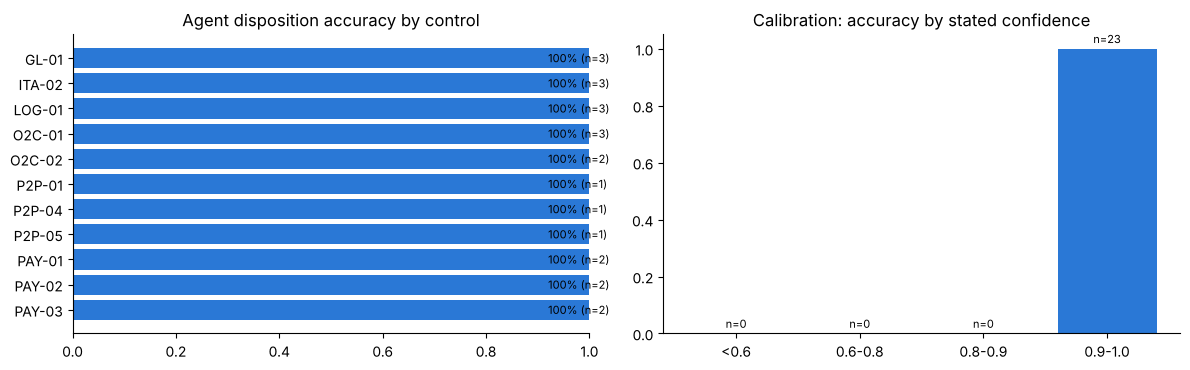

,n,acc
confidence,,
<0.6,0,NaN
0.6-0.8,0,NaN
0.8-0.9,0,NaN
0.9-1.0,23,1.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
per = ev.groupby("control_id").agg(n=("correct", "size"), accuracy=("correct", "mean")).sort_index()
ax[0].barh(per.index, per.accuracy, color="#2a78d6"); ax[0].set_xlim(0, 1); ax[0].set_title("Agent disposition accuracy by control"); ax[0].invert_yaxis()
for i, (a, n) in enumerate(zip(per.accuracy, per.n)): ax[0].text(min(a, 0.9) + 0.02, i, f"{a:.0%} (n={n})", va="center", fontsize=8)
bins = pd.cut(ev.confidence, [0, 0.6, 0.8, 0.9, 1.0001], labels=["<0.6", "0.6-0.8", "0.8-0.9", "0.9-1.0"], include_lowest=True)
cal = ev.groupby(bins, observed=False).agg(n=("correct", "size"), acc=("correct", "mean"))
ax[1].bar(cal.index.astype(str), cal.acc.fillna(0), color="#2a78d6"); ax[1].set_ylim(0, 1.05); ax[1].set_title("Calibration: accuracy by stated confidence")
for i, (a, n) in enumerate(zip(cal.acc.fillna(0), cal.n)): ax[1].text(i, a + 0.02, f"n={n}", ha="center", fontsize=8)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
cal

In [18]:
# Every case the agent got wrong (disposition or severity), with its own explanation
wrong = ev[~ev.correct | (ev.is_breach & (ev.disposition=="breach") & (ev.severity != ev.expected_sev))]
wrong[["ref", "control_id", "truth", "disposition", "severity", "expected_sev", "confidence", "faithful"]].assign(
    explanation=wrong.ai.apply(lambda a: a["explanation"][:220]), scenario=wrong.gtrow.apply(lambda g: g["scenario"] if g else ""))

,ref,control_id,truth,disposition,severity,expected_sev,confidence,faithful,explanation,scenario


In [19]:
# Unverified citations flagged by the faithfulness checker
ev[~ev.faithful][["ref", "control_id", "unverified"]].assign(explanation=lambda d: d.index.map(lambda i: ev.loc[i, "ai"]["explanation"][:200]))

,ref,control_id,unverified,explanation
17,EXC-0002-010,PAY-01,"[25,000]",The employee Salman Butt (E-10039) is a contract worker with 30 contracted hours per week (see employee record E-100...


## 6. Prompt v1 (single call, no tools) vs the agent - was the agent worth it?

Phase 1 classified this use case as *AI, not agentic*. Before keeping the agent, I ran the simplest version, **prompt v1**: one call, the same evidence, JSON output, no tools and no rubric-specific instructions. I ran it on the batch-1 exceptions through `POST /api/eval/baseline`, which leaves the agent's stored proposals untouched, and scored it the same way.

In [20]:
BASE_CACHE = RES / "baseline_v1_runs.json"
if not BASE_CACHE.exists():
    rows = []
    for _, e in ev[ev.batch_no == 1].iterrows():
        while True:
            r = sup.post(f"{BASE}/api/eval/baseline", json={"id": int(e.id)})
            if r.status_code == 429: time.sleep(min(90, int(r.json().get("retryAfter") or 30))); continue
            r.raise_for_status(); rows.append(r.json()); break
        print(rows[-1]["ref"], rows[-1]["assessment"]["disposition"], rows[-1]["assessment"]["severity"], rows[-1]["usage"]["total_tokens"])
    json.dump(rows, open(BASE_CACHE, "w"))
base = pd.DataFrame(json.load(open(BASE_CACHE)))
b = ev.set_index("ref").loc[base.ref].reset_index()
b = b.assign(disposition=base.assessment.apply(lambda a: a["disposition"]).values, severity=base.assessment.apply(lambda a: a["severity"]).values,
             confidence=base.assessment.apply(lambda a: a["confidence"]).values, faithful=base.assessment.apply(lambda a: a["faithfulness"]["ok"]).values)
b["correct"] = (b.is_breach & (b.disposition=="breach")) | (~b.is_breach & (b.disposition=="false_positive"))
same = ev[ev.ref.isin(base.ref)]
cmp_ = pd.concat([metrics(b).rename("prompt v1: single call"), metrics(same).rename("prompt v4: agent")], axis=1)
toks = pd.DataFrame(sup.get(f"{BASE}/api/export?what=agent_runs").json()["rows"])
cmp_.loc["mean tokens / exception"] = [base.usage.apply(lambda u: u["total_tokens"]).mean(), toks[(toks.kind=="triage") & toks.ok & toks.exception_id.isin(same.id)].total_tokens.mean()]
cmp_

,prompt v1: single call,prompt v4: agent
exceptions assessed,8.000,8.000
true breaches,6.000,6.000
decoys,2.000,2.000
false-clear rate,0.000,0.000
false-clear rate (conf>=0.8),0.000,0.000
severity agreement,1.000,1.000
faithfulness (all citations verified),1.000,1.000
precision of AI 'breach',1.000,1.000
decoy clearance,1.000,1.000
false-alarm rate on decoys,0.000,0.000


## 7. Failure 2: the agent looped and never answered (prompt v3)

The first live agent run (prompt v3, max 5 calls, `tool_choice` forced to `submit_assessment` on the last call) failed on a freight exception. The model:
1. looked up the route (useful),
2. then searched for `diversion_note = "*"` **twice** (a wildcard the tool does not support),
3. then searched for a `notes` field that does not exist,
4. and on the forced last call **ignored the forced tool choice**. Groq rejected the call (`tool_use_failed`), so the exception came back as *needs more info* after 5,737 tokens.

The saved trace:

In [21]:
f = json.load(open("dev_log/03_agent_v3_failure_no_submit.json"))
print(f["exception"], f["control"], f["prompt_version"], f["run"])
for s in f["steps"]:
    if s["type"] == "tool": print("  tool:", s["name"], s["arguments"], "->", s["result_preview"][:80])
    if s["type"] == "error": print("  ERROR:", s["error"][:200])

EXC-0001-002 LOG-01 triage-agent-v3 {'total_tokens': 5737, 'llm_calls': 4, 'cost_usd': 0.00123, 'latency_ms': 3951}
  tool: get_record {'record_id': 'RT-05'} -> {"record_type":"route","id":"RT-05","km":185,"origin":"LHR","destination":"Faisa
  tool: search_records {'field': 'diversion_note', 'value': '*', 'record_type': 'freight_bill'} -> {"count":0,"results":[]}
  tool: search_records {'field': 'diversion_note', 'value': '*', 'record_type': 'freight_bill'} -> {"count":0,"results":[]}
  tool: search_records {'field': 'notes', 'value': 'diversion', 'record_type': 'freight_bill'} -> {"count":0,"results":[]}
  ERROR: Groq 400: {"message":"Tool call validation failed: tool call validation failed: attempted to call tool 'search_records' which does not match request.tool_choice: 'submit_assessment'","type":"invalid_r


**What I changed (prompt/loop v4):**
* The prompt states that evidence fields are complete extracts ("an empty approval or note field means the document does not exist"), forbids searching for documents nothing refers to, and gives a **lookup budget** (≤ 3; most cases need 0-2).
* The loop counts lookups. When the budget is used, or on the last call, it offers **only** the `submit_assessment` tool with `tool_choice: "required"`, instead of relying on the model to obey a forced choice among several tools.
* Max model calls dropped from 5 to 4.

On the same exception, v4 submitted a correct *breach / Low* in **1 call and 1,717 tokens**. Across the evaluation set the number of calls per exception is shown in section 8.

### Failure 3 and onwards: what the evaluation itself found
The cases listed in section 5 ("every case the agent got wrong") are the live failures. They are discussed in the honesty section.

## 8. Tokens and cost

Prices: Groq on-demand for `openai/gpt-oss-120b`, **$0.15 / M input, $0.075 / M cached input, $0.60 / M output** (third-party trackers of Groq pricing, Oct 2026; held in `lib/ai/groq.ts`). Token counts come from the `usage` field Groq returns on every call. They are measured, not estimated.

In [22]:
toks = pd.DataFrame(sup.get(f"{BASE}/api/export?what=agent_runs").json()["rows"])
t = toks[(toks.kind=="triage") & toks.ok & toks.exception_id.isin(ev.id)]
summary = pd.Series({
    "exceptions": len(t), "model calls": t.llm_calls.sum(), "calls / exception": t.llm_calls.mean(),
    "prompt tokens": t.prompt_tokens.sum(), "completion tokens (incl. reasoning)": t.completion_tokens.sum(), "cached tokens": t.cached_tokens.sum(),
    "total tokens": t.total_tokens.sum(), "tokens / exception (mean)": t.total_tokens.mean(), "tokens / exception (max)": t.total_tokens.max(),
    "cost USD (total)": t.cost_usd.sum(), "cost USD / exception": t.cost_usd.mean(),
    "latency p50 s (incl. rate-limit waits)": t.latency_ms.median()/1000, "latency p95 s": t.latency_ms.quantile(.95)/1000,
})
summary.to_frame("evaluation run (agent, prompt v4)")

,"evaluation run (agent, prompt v4)"
exceptions,23.000000
model calls,34.000000
calls / exception,1.478261
prompt tokens,43533.000000
completion tokens (incl. reasoning),12908.000000
cached tokens,16384.000000
total tokens,56441.000000
tokens / exception (mean),2453.956522
tokens / exception (max),3966.000000
cost USD (total),0.013046


In [23]:
# A representative single run: the median-token exception, step by step
rep = t.iloc[(t.total_tokens - t.total_tokens.median()).abs().argsort().iloc[0]]
e = ev[ev.id == rep.exception_id].iloc[0]
print(f"{e.ref} {e.control_id}: {e.ai['disposition']} / {e.ai['severity']}  conf {e.ai['confidence']}")
print(f"tokens {rep.total_tokens} (in {rep.prompt_tokens}, out {rep.completion_tokens}, cached {rep.cached_tokens}), {rep.llm_calls} calls, ${rep.cost_usd:.5f}, {rep.latency_ms} ms")
for s in rep.steps:
    if s["type"] == "llm": print(f'  model call {s["step"]}: {s["usage"]["prompt_tokens"]} in / {s["usage"]["completion_tokens"]} out, {s["latency_ms"]} ms ->', [c["name"] for c in s.get("tool_calls") or []])
    if s["type"] == "tool": print(f'  tool {s["name"]}({s["arguments"]})')
print("\nExplanation:", e.ai["explanation"])

EXC-0002-001 P2P-01: false_positive / None  conf 0.95
tokens 2048 (in 1462, out 586, cached 0), 1 calls, $0.00057, 6913.0 ms
  model call 1: 1462 in / 586 out, 1834 ms -> ['submit_assessment']

Explanation: Invoices APV-002-0041 (gross PKR 700,719, service period Jun 2026) and APV-002-0042 (gross PKR 700,719, service period Jul 2026) are from the same vendor for labour contractor services and cover different monthly service periods, matching the accepted legitimate explanation for recurring fixed‑fee services.


In [24]:
# Projection to production volume (assumption-driven, labelled as such)
per_exc = t.cost_usd.mean(); tok_exc = t.total_tokens.mean()
exc_per_batch = ing.exceptions.mean()
scen = pd.DataFrame([
    {"scenario": "This demo design: weekly extract, 15 controls", "exceptions / year": exc_per_batch * 52},
    {"scenario": "Nightly extract, same exception rate per record", "exceptions / year": exc_per_batch * 365},
    {"scenario": "Full org (Phase 1: ~40k PO lines; 10x records, same rate)", "exceptions / year": exc_per_batch * 365 * 10},
])
scen["tokens / year"] = scen["exceptions / year"] * tok_exc
scen["model cost USD / year"] = scen["exceptions / year"] * per_exc
scen.round(2)

,scenario,exceptions / year,tokens / year,model cost USD / year
0,"This demo design: weekly extract, 15 controls",704.60,1.729058e+06,0.40
1,"Nightly extract, same exception rate per record",4945.75,1.213666e+07,2.81
2,"Full org (Phase 1: ~40k PO lines; 10x records, same rate)",49457.50,1.213666e+08,28.05


Model cost is negligible next to the Phase 1 baseline of about 2,000 auditor hours a year. The real costs are the in-country hosting required by the Phase 1 verdict (a GPU server for gpt-oss-120b, or gpt-oss-20b on smaller hardware) and the supervisor's review time. Hosting the demo costs nothing (Vercel Hobby, Neon free tier, Groq free tier). The binding constraint in this demo was the free tier's **8,000 tokens/minute and ~200,000 tokens/day**, not money.

## 9. The other AI features: copilot and committee report (one call each, with cost)

In [25]:
COP_CACHE = RES / "copilot_report.json"
if not COP_CACHE.exists():
    q = "Which controls have the most AI-proposed breaches, and what is the largest open amount at risk? Cite the exception refs."
    c = sup.post(f"{BASE}/api/copilot", json={"messages": [{"role": "user", "content": q}]}).json()
    rp = sup.post(f"{BASE}/api/report").json()["report"]
    json.dump({"q": q, "copilot": c, "report": rp}, open(COP_CACHE, "w"))
cr = json.load(open(COP_CACHE))
print("Q:", cr["q"]); print("A:", cr["copilot"]["answer"]); print("tools:", [s["tool"] for s in cr["copilot"]["steps"]], "| tokens", cr["copilot"]["usage"]["total_tokens"], "| $%.5f" % cr["copilot"]["cost_usd"], "| faithfulness", cr["copilot"]["faithfulness"]["ok"], cr["copilot"]["faithfulness"]["unverified"])
print("\n--- Committee report ---\n" + cr["report"]["text"][:1800])
print("\nreport tokens", cr["report"]["usage"]["total_tokens"], "| faithfulness", cr["report"]["faithfulness"]["ok"], cr["report"]["faithfulness"]["unverified"])

Q: Which controls have the most AI-proposed breaches, and what is the largest open amount at risk? Cite the exception refs.
A: **Control with the most AI‑proposed breaches**

| Control | AI‑proposed breaches (open) | Total open amount at risk (PKR) |
|---------|----------------------------|---------------------------------|
| **GL‑01 – Self‑approved / unapproved manual journals** | **3** | **2,830,000** |

**Why GL‑01 tops the list**

- The exposure‑by aggregation shows GL‑01 with the highest count of AI‑proposed breaches (3) and the largest cumulative amount at risk (PKR 2,830,000).  
- No other control exceeds either the breach count or the amount at risk (the next highest is O2C‑01 with 2 breaches and PKR 2,241,636).

**Exception references for the open GL‑01 breaches**

The system currently has the three GL‑01 exceptions in *NEW* status, but none of them have been tagged with an AI disposition of **breach** yet, so there are no AI‑proposed breach refs to cite at this moment. The op

### Failure 3 (found in this run): the copilot contradicted itself
Read the answer above closely. The copilot says GL-01 has 3 AI-proposed breaches worth PKR 2,830,000. It then says none of the GL-01 items is tagged as a breach, and cites three exceptions that are still **queued and unassessed** (from later batches). Two tools with different filters (`exposure_by` counts AI-proposed breaches; `query_exceptions` returned all GL-01 items sorted by amount) were blended into one answer. The faithfulness check passed, because every figure exists in the data; it checks figures, not logic. **Status: partially fixed after this run.** The copilot prompt now defines "open breach", and `query_exceptions` gained an `open_breaches_only` filter. That change caused a *new* failure: the model sent `status` as a list, Groq rejected the call with `tool_use_failed`, and the copilot errored. Fix: statuses are accepted comma-separated, and the copilot loop retries after a malformed tool call. A single re-test returned the correct top-5 open breaches (one query, 10/10 figures verified). That is one test, not an evaluation, so I still do not use copilot answers as audit evidence. The cached answer above is the original, failing one.

Also visible in section 5: the verifier flagged "25,000" in a correct explanation (40,000 × 30/48, a pro-rated minimum wage). That is a **verifier false alarm**: it accepts sums and differences of evidence figures, but not products.

## 10. The human loop, end to end (through the same API the UI uses)

The supervisor confirms one AI-proposed breach. The approver tries to act on an item they did not review, then approves it, which raises a corrective action. The supervisor submits remediation evidence, and only the approver can close it. The audit trail records each step.

In [26]:
WF_CACHE = RES / "workflow_demo.json"
if not WF_CACHE.exists():
    target = ev[(ev.disposition=="breach") & ev.is_breach].iloc[0]
    steps = []
    steps.append(("supervisor tries to approve (should fail: role)", sup.post(f"{BASE}/api/exceptions/{target.id}/approve", json={"decision": "approve"}).json()))
    steps.append(("supervisor confirms breach", sup.post(f"{BASE}/api/exceptions/{target.id}/review", json={"decision": "confirm", "severity": target.severity, "note": "Evidence checked against source records"}).json()))
    steps.append(("approver approves finding", appr.post(f"{BASE}/api/exceptions/{target.id}/approve", json={"decision": "approve", "note": "Agreed"}).json()))
    act = [a for a in appr.get(f"{BASE}/api/actions").json()["rows"] if a["exception_id"] == target.id][0]
    steps.append(("approver tries to close before evidence (should fail)", appr.post(f"{BASE}/api/actions/{act['id']}", json={"op": "close"}).json()))
    steps.append(("supervisor submits remediation evidence", sup.post(f"{BASE}/api/actions/{act['id']}", json={"op": "submit", "management_response": "Agreed; process owner to recover and fix", "remediation_evidence": "Recovery note and system configuration change screenshot filed"}).json()))
    steps.append(("approver verifies and closes", appr.post(f"{BASE}/api/actions/{act['id']}", json={"op": "close", "note": "Evidence verified"}).json()))
    trail = [l for l in sup.get(f"{BASE}/api/activity").json()["rows"] if l["entity"] in (target.ref, act["ref"])]
    json.dump({"ref": target.ref, "steps": steps, "trail": trail}, open(WF_CACHE, "w"))
wf = json.load(open(WF_CACHE))
print("Exception", wf["ref"])
for s, r in wf["steps"]: print(f"  {s:55s} -> {r}")
pd.DataFrame(wf["trail"])[["at", "actor", "role", "action", "entity", "detail"]].sort_values("at").tail(6)   # this run only

Exception EXC-0001-001
  supervisor tries to approve (should fail: role)         -> {'error': 'This action needs role: approver'}
  supervisor confirms breach                              -> {'ok': True}
  approver approves finding                               -> {'ok': True}
  approver tries to close before evidence (should fail)   -> {'error': 'Action is not awaiting verification'}
  supervisor submits remediation evidence                 -> {'ok': True}
  approver verifies and closes                            -> {'ok': True}


,at,actor,role,action,entity,detail
5,2026-10-31T16:25:25.824Z,Head of Internal Audit (demo),approver,ACTION_CLOSE,CA-0001,verified
4,2026-10-31T16:40:31.569Z,AI agent (started by Audit Supervisor (demo)),agent,AI_PROPOSAL,EXC-0001-001,breach / High (confidence 0.95)
3,2026-10-31T16:46:48.877Z,Audit Supervisor (demo),supervisor,SUPERVISOR_CONFIRMED,EXC-0001-001,Severity High. Evidence checked against source records
2,2026-10-31T16:46:48.889Z,Head of Internal Audit (demo),approver,FINDING_APPROVED,EXC-0001-001,"Corrective action CA-0001 raised for Head of Sales, due in 14 days"
1,2026-10-31T16:46:48.915Z,Audit Supervisor (demo),supervisor,ACTION_SUBMIT,CA-0001,Agreed; process owner to recover and fix
0,2026-10-31T16:46:48.922Z,Head of Internal Audit (demo),approver,ACTION_CLOSE,CA-0001,Evidence verified


## 11. Results against the Phase 1 evaluation plan

Read this table together with the honesty section. The AI rows come from 23 exceptions, so 0% false clears is consistent with a true rate of up to about 21%; it does **not** demonstrate the ≤ 2% target. The baseline in section 6 matched the agent at half the tokens. Confidence was 0.95-0.98 on every case, so it carries no information.

In [27]:
ruler = gt[gt.kind=="breach"].detected.mean()
prec_ai = agent_m["precision of AI 'breach'"]
res = pd.DataFrame([
    ["Per-control detection recall (seeded breaches)", ">= 95%", f"{ruler:.1%} overall; min per control {rule.recall.min():.0%}", f"{len(gt[gt.kind=='breach'])} breaches, {EVAL_RULE_BATCHES} batches"],
    ["Transaction coverage per control", "100%", "100% (every record of the tested type)", f"{runs.population.sum():,} tests"],
    ["Time from failure to exception", "<= 7 days", "<= 6 days (weekly window); same ingestion run", "design"],
    ["False-clear rate (7a)", "<= 2%", f"{agent_m['false-clear rate']:.1%}", f"n={int(agent_m['true breaches'])} true-breach exceptions"],
    ["False-clear rate, confidence >= 0.8 (7a)", "<= 2%", f"{agent_m['false-clear rate (conf>=0.8)']:.1%}", ""],
    ["Precision of AI-proposed exceptions", ">= 70%", f"{prec_ai:.1%}", ""],
    ["Rating (severity) agreement", ">= 85%", f"{agent_m['severity agreement']:.1%}", "vs rubric, not a senior auditor"],
    ["Explanation faithfulness", ">= 95%", f"{agent_m['faithfulness (all citations verified)']:.1%}", f"n={int(agent_m['exceptions assessed'])}"],
], columns=["Phase 1 metric", "target", "result", "basis"])
res

,Phase 1 metric,target,result,basis
0,Per-control detection recall (seeded breaches),>= 95%,100.0% overall; min per control 100%,"24 breaches, 20 batches"
1,Transaction coverage per control,100%,100% (every record of the tested type),"2,103 tests"
2,Time from failure to exception,<= 7 days,<= 6 days (weekly window); same ingestion run,design
3,False-clear rate (7a),<= 2%,0.0%,n=14 true-breach exceptions
4,"False-clear rate, confidence >= 0.8 (7a)",<= 2%,0.0%,
5,Precision of AI-proposed exceptions,>= 70%,100.0%,
6,Rating (severity) agreement,>= 85%,100.0%,"vs rubric, not a senior auditor"
7,Explanation faithfulness,>= 95%,95.7%,n=23


## 12. Honesty section

*(Also in `docs/HONESTY.md`.)*


## What the system gets wrong, or where it can't yet be trusted

1. **The headline AI scores are an upper bound, not a production estimate.** On the evaluation set the agent made no disposition errors and no severity errors (23 exceptions: 14 true breaches, 9 decoys). This needs three qualifications:
   * **The sample is small.** Zero false clears in 14 true breaches is consistent with a true false-clear rate of up to about 21% (rule of three, 95% confidence). The Phase 1 target of ≤ 2% has **not been demonstrated**; demonstrating it needs at least ~150 true-breach exceptions. I was limited by the Groq free tier (8,000 tokens/minute, ~200,000 tokens/day, shared with the live demo). Phase 1 planned a gold set of 200 items; I ran 23.
   * **The decoys are cleaner than real evidence.** I wrote the generator, so each legitimate explanation is a clear sentence in a named field ("Call-back to registered contact by Treasury..."). Real evidence is scanned PDFs, partial e-mails, approvals in WhatsApp and missing fields. The agent has not been tested on ambiguous, contradictory or adversarial evidence, such as a forged approval memo.
   * **The ground truth and the severity rubric are mine**, not a senior auditor's. "Severity agreement 100%" means the agent applied *my written rubric* correctly. It does not mean it matches a senior auditor's judgement, which was the Phase 1 metric.
2. **Confidence scores carry no information.** All 23 confidences were between 0.95 and 0.98. The calibration chart has a single bucket. A supervisor cannot use confidence to decide what to scrutinise, so the UI must not invite them to, and "high-confidence false-clear rate" says nothing extra here. This is the automation-bias risk Phase 1 raised: fluent, uniformly confident proposals.
3. **The agent was not shown to be better than one prompt.** On the 8 batch-1 cases, the single-call prompt v1 (no tools) was as accurate as the agent at **46% of the tokens** (1,007 vs 2,197 per exception). I kept the agent because some decoys' explanations sit in a *related* record (a bank-change verification, an employee's HR file) that a single call would not see unless the rule pre-attached it. But batch 1 contained no such case. The comparison does not prove the agent's extra cost buys anything, and with more time I would run both on the related-record controls (P2P-05, PAY-02, ITA-02) specifically.
4. **The copilot contradicted itself.** Asked which controls have the most AI-proposed breaches, it answered "GL-01, 3 breaches, PKR 2,830,000". In the same answer it said none of the GL-01 items had been tagged as a breach, then listed three exceptions that were still **queued, unassessed** ones from later batches. The cause is two tools with different filters (`exposure_by` counts AI-proposed breaches; `query_exceptions` sorted all GL-01 items by amount), which the model merged. The faithfulness check passed, because the numbers were real; it checks figures, not logic. **Partial fix, made after the evaluation run:** the copilot prompt now defines "open breach", and `query_exceptions` has an `open_breaches_only` filter. That fix caused a new failure: the model passed `status` as a list, Groq rejected the tool call (`tool_use_failed`) and the copilot returned an error. I now accept comma-separated statuses and the loop retries after a malformed call. After both fixes, the same question gave a correct answer (one query, 10/10 figures verified), but that is **one test, not an evaluation**. **I would not let the copilot's answers go into a report without checking.**
5. **The faithfulness verifier has false alarms and blind spots.** It flagged "PKR 25,000" in a correct explanation (40,000 × 30/48, the pro-rated minimum wage) because it only accepts sums and differences of evidence figures. It would also *pass* a wrong statement built from correct numbers, such as citing the right amount on the wrong invoice. It checks that figures exist in the evidence, not that the reasoning is right.
6. **The rules have only been tested on a clean base population.** No exception was raised on the clean background transactions, because the generator keeps them clean. Real SAP data has noise (credit memos, reversals, partial deliveries, legitimately re-keyed invoices), so rule precision would be lower and the supervisor's queue longer. Rule thresholds such as the 45-day duplicate window and the 7-day split window are untuned guesses.
7. **The minimum wage and other parameters are configured values**, not read from the provincial notifications (PKR 40,000 for all three provinces is a parameter to be verified). The weekly-hours cap of 60 is a company-policy assumption, not a citation of each Factories Act.

## What I would not yet put in front of a customer

* **Anything with real data on this deployment.** The Phase 1 verdict is *Go, with in-country compute*. This demo sends prompts to a hosted model outside Pakistan. It is acceptable only because the data is synthetic. Production must run gpt-oss on Company or in-country infrastructure, which needs no code change beyond the endpoint, but the hosting, the latency and the 120b model's hardware needs are untested.
* **The audit committee report and the copilot** (see item 4). They read well, which is exactly the risk.
* **Any dashboard rating as a stand-alone assurance statement.** The "Effective (provisional)" rating shows when exceptions are still queued for the AI. A committee member could read that as assurance.
* **The access model.** Demo accounts with passwords printed on the login page, a shared demo database that any visitor can change, no SSO, no per-process-owner access (Phase 1 required role-based access so each owner sees only their own controls; process owners have no logins here, and the supervisor records their responses for them).
* **The data connector.** There is no SAP extract. "Fetch" generates the next synthetic week, and extract windows run past today's date if you fetch many times.
* **Continuous operation.** On the Vercel Hobby plan the scheduled run is once a day, and the free Groq tier would stall the agent on a busy day. The worker loop runs in the browser of whoever is signed in; with nobody signed in, only the daily cron processes the queue (up to ~40 seconds of work).

## What it cost to run

| Item | Measured |
|---|---|
| Agent evaluation run (23 exceptions, prompt v4) | 56,441 tokens (43,533 in, of which 16,384 cached; 12,908 out incl. reasoning) · 34 model calls · **$0.013** |
| Per exception | mean 2,454 tokens (max 3,966) · 1.48 model calls · **$0.00057** · p50 10.5 s, p95 20.4 s (includes free-tier rate-limit waits) |
| Prompt v1 baseline (8 exceptions) | ~1,007 tokens/exception |
| Failed v3 agent run (the loop bug) | 5,737 tokens for one exception |
| Projection: nightly extracts, ~4,900 exceptions/year | ~$2.8/year in model tokens |
| Hosting this demo | $0 (Vercel Hobby, Neon free, Groq free tier) |

Model spend is not the real cost. The real costs are (a) in-country GPU hosting for gpt-oss-120b, needed by the Phase 1 verdict and not yet priced, and (b) the supervisor's and approver's review time, which the system moves around rather than removes. Every exception still needs two people.

Development cost: the AI coding assistant wrote most of the code under my direction. I have reviewed the design and can explain each part: the rules, the agent loop, the verifier and the workflow.